![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 2 · Versión resuelta · referencia</div><div style="font-size:22px;font-weight:700;margin-top:4px">L2.1 · Clustering: k-means, DBSCAN y mezclas de gaussianas</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Agrupar datos **sin etiquetas** con los dos algoritmos que todo científico de datos debe dominar, **k-means** y **DBSCAN**, saber cuándo falla cada uno y comparar con una mezcla de gaussianas. |
| **Duración** | ≈ 90 min con el reto · la parte 1 es el prelaboratorio y en el taller de la **Clase 2** (35 min) se completan las partes 2 a 4 |
| **Teoría** | Manual M2 §6–§7 · Animaciones A2.1 a A2.4 y A2.13 |
| **Datos icónicos** | nubes sintéticas (`make_blobs`), **lunas** (`make_moons`), **flores Iris** (Fisher, 1936) y **vinos** (scikit-learn) |
| **Escala realista (reto)** | **dígitos escritos a mano** sin etiquetas: 1 797 imágenes de scikit-learn y 10 000 de **MNIST** |

**Partes:** 1 · k-means paso a paso y la elección de k → 2 · escalar antes de medir distancias → 3 · DBSCAN: densidad y ruido → 4 · mezclas de gaussianas (GMM) → reto: agrupar dígitos sin decirle al algoritmo cuál es cuál.

En el aprendizaje **no supervisado** no hay una columna `y` que predecir. Aun así, en los ejemplos icónicos guardamos las etiquetas verdaderas **solo para evaluar** al final (con el índice de Rand ajustado, ARI): el algoritmo nunca las ve.

## 0 · Configuración

In [1]:
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
COLORES = ["#004890", "#C2410C", "#A87900", "#3A7D44", "#6B4C9A", "#1B8A8F", "#B23A48", "#5C6B73", "#D08C2E", "#2F5D8A"]
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=COLORES), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
CACHE = os.path.expanduser("~/.cache/ml-unibe")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"


def descargar(nombre):
    """Descarga un archivo del repositorio público de datasets de Keras (una sola vez)."""
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL + nombre, ruta)
    return ruta


def dibujar_grupos(ax, X, etiquetas, titulo, centros=None):
    """Dispersión coloreada por grupo; el ruido (etiqueta -1) va en gris con una ×."""
    etiquetas = np.asarray(etiquetas)
    for k in np.unique(etiquetas):
        m = etiquetas == k
        if k == -1:
            ax.scatter(X[m, 0], X[m, 1], s=18, c="#9AA0A6", marker="x", label="ruido")
        else:
            ax.scatter(X[m, 0], X[m, 1], s=14, color=COLORES[k % len(COLORES)], alpha=0.85)
    if centros is not None:
        ax.scatter(centros[:, 0], centros[:, 1], s=220, marker="*", c="white", edgecolors="black", linewidths=1.3)
    ax.set_title(titulo, fontsize=10)


print(f"scikit-learn {sklearn.__version__} · semilla {SEED}")

scikit-learn 1.9.1 · semilla 2026


## Parte 1 · k-means paso a paso y la elección de k

k-means busca **k centroides** que minimicen la suma de distancias al cuadrado de cada punto a su centroide más cercano (la **inercia**). Alterna dos pasos hasta que nada cambia (A2.1):

1. **Asignar:** cada punto va al centroide más cercano.
2. **Actualizar:** cada centroide se mueve al promedio de sus puntos.

Lo programamos a mano en pocas líneas con NumPy para ver que no hay magia, y luego comparamos con scikit-learn.

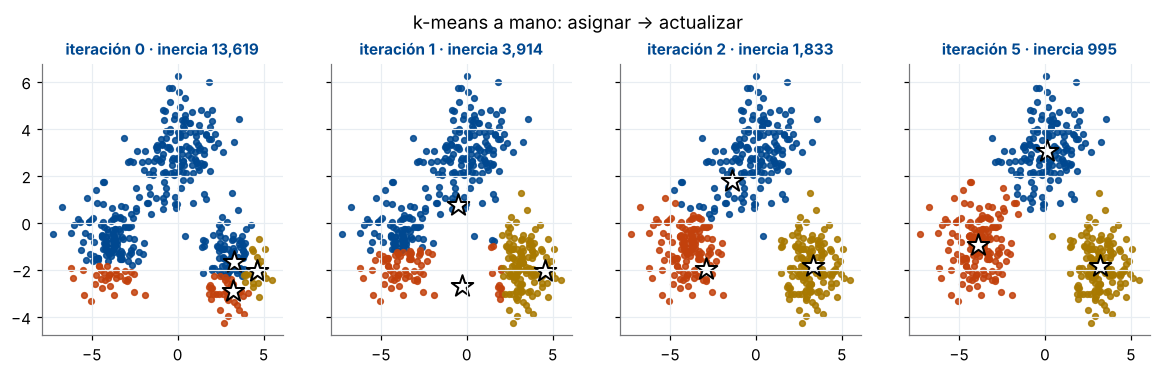

In [2]:
from sklearn.datasets import make_blobs

X_b, y_b = make_blobs(n_samples=450, centers=[[-4, -1], [0, 3], [3, -2]], cluster_std=[1.0, 1.2, 0.9], random_state=SEED)


def kmeans_a_mano(X, k, iteraciones=10, semilla=0):
    """k-means de Lloyd: devuelve las asignaciones y la historia de centroides e inercias."""
    rng = np.random.default_rng(semilla)
    C = X[rng.choice(len(X), k, replace=False)]          # k puntos al azar como centroides iniciales
    historia = []
    for _ in range(iteraciones):
        d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)   # distancia² de cada punto a cada centroide
        asign = d2.argmin(axis=1)                                  # paso 1: asignar
        inercia = d2[np.arange(len(X)), asign].sum()
        historia.append((C.copy(), asign.copy(), inercia))
        C = np.array([X[asign == j].mean(axis=0) if np.any(asign == j) else C[j] for j in range(k)])  # paso 2
    return asign, historia


asign, hist = kmeans_a_mano(X_b, 3, iteraciones=6, semilla=3)
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True, sharey=True)
for ax, t in zip(axs, [0, 1, 2, 5]):
    C, a, inercia = hist[t]
    dibujar_grupos(ax, X_b, a, f"iteración {t} · inercia {inercia:,.0f}", centros=C)
plt.suptitle("k-means a mano: asignar → actualizar", y=1.03); plt.show()

**Tu turno.** Compara tu k-means con el de scikit-learn (`KMeans(n_clusters=3, n_init=10, random_state=SEED)`). La inercia final debe coincidir casi exactamente. Mide también el acuerdo con las etiquetas verdaderas con el **ARI** (`adjusted_rand_score`): 1 = agrupación perfecta, ≈ 0 = al azar.

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# TODO: entrena KMeans de scikit-learn, guarda su inercia (atributo inertia_) y calcula el ARI de ambos.
km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_b)
inercia_sk = km.inertia_
ari_mano = adjusted_rand_score(y_b, hist[-1][1])
ari_sk = adjusted_rand_score(y_b, km.labels_)
print(f"Inercia a mano = {hist[-1][2]:,.1f} · scikit-learn = {inercia_sk:,.1f}")
print(f"ARI a mano = {ari_mano:.3f} · scikit-learn = {ari_sk:.3f}")
assert abs(hist[-1][2] - inercia_sk) / inercia_sk < 0.01, "Las dos inercias deberían coincidir."

Inercia a mano = 994.6 · scikit-learn = 994.2
ARI a mano = 0.967 · scikit-learn = 0.967


### ¿Cuántos grupos? El codo y la silueta

En la vida real no sabemos k. Dos herramientas (A2.4):

- **Codo:** la inercia siempre baja al subir k; buscamos el punto donde deja de bajar mucho.
- **Silueta:** para cada punto, \(s = (b - a) / \max(a, b)\), con \(a\) la distancia media a su grupo y \(b\) la distancia media al grupo vecino más cercano. Va de −1 a 1; más alto es mejor.

Lo aplicamos al conjunto icónico de **Iris** sin mirar la especie.

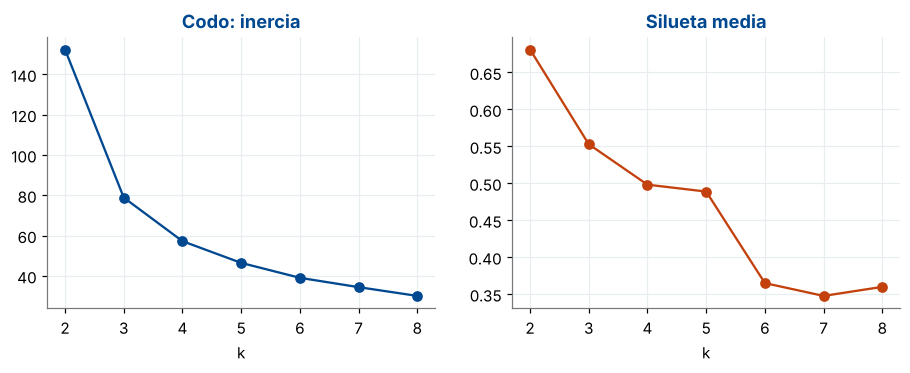

 k  inercia  silueta   ARI
 2  152.348    0.681 0.540
 3   78.851    0.553 0.730
 4   57.228    0.498 0.650
 5   46.446    0.489 0.608
 6   39.040    0.365 0.448
 7   34.409    0.348 0.479
 8   30.065    0.360 0.457


In [4]:
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score

iris = load_iris()
X_i, y_i = iris.data, iris.target
filas = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_i)
    filas.append({"k": k, "inercia": m.inertia_, "silueta": silhouette_score(X_i, m.labels_), "ARI": adjusted_rand_score(y_i, m.labels_)})
codo = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(codo["k"], codo["inercia"], "o-"); axs[0].set_title("Codo: inercia"); axs[0].set_xlabel("k")
axs[1].plot(codo["k"], codo["silueta"], "o-", color=UNIBE["naranja"]); axs[1].set_title("Silueta media"); axs[1].set_xlabel("k")
plt.show()
print(codo.round(3).to_string(index=False))

La silueta prefiere **k = 2**, aunque hay tres especies: *versicolor* y *virginica* se solapan y, sin etiquetas, parecen un solo grupo. El ARI (que usa las etiquetas que el algoritmo no vio) es mejor con k = 3. **Lección:** las métricas internas miden la forma de los grupos, no si coinciden con las categorías que a ti te interesan.

## Parte 2 · Escalar antes de medir distancias

k-means usa distancias euclidianas: una variable con números grandes domina a las demás (A2.2). El conjunto de **vinos** de scikit-learn tiene 13 medidas químicas de tres variedades; la *prolina* va de 278 a 1 680 y el *tono* de 0,48 a 1,71.

In [5]:
from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

vino = load_wine()
X_w, y_w = vino.data, vino.target
cols = ["proline", "magnesium", "alcalinity_of_ash", "color_intensity", "hue"]
print(pd.DataFrame(X_w, columns=vino.feature_names)[cols].describe().loc[["min", "max", "std"]].round(2).T.to_string())

                      min      max     std
proline            278.00  1680.00  314.91
magnesium           70.00   162.00   14.28
alcalinity_of_ash   10.60    30.00    3.34
color_intensity      1.28    13.00    2.32
hue                  0.48     1.71    0.23


**Tu turno.** Agrupa los vinos en 3 grupos **sin escalar** y **con `StandardScaler`** (dentro de un pipeline). Compara el ARI.

In [6]:
# TODO: calcula ari_sin (KMeans sobre X_w) y ari_con (pipeline StandardScaler + KMeans).
ari_sin = adjusted_rand_score(y_w, KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_w))
pipe = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=SEED))
ari_con = adjusted_rand_score(y_w, pipe.fit_predict(X_w))
print(f"ARI sin escalar = {ari_sin:.3f} · con StandardScaler = {ari_con:.3f}")
assert ari_con > ari_sin + 0.3, "Escalar debería mejorar mucho el acuerdo con las variedades."

ARI sin escalar = 0.371 · con StandardScaler = 0.897


Sin escalar, k-means agrupa casi solo por prolina. Escalar no es un detalle técnico: **decide qué significa «parecido»**.

## Parte 3 · DBSCAN: densidad y ruido

k-means supone grupos **redondos y de tamaño parecido**, y obliga a cada punto a pertenecer a algún grupo. DBSCAN (Ester y colaboradores, 1996) piensa distinto (A2.3):

- Un punto es **núcleo** si tiene al menos `min_samples` vecinos a distancia ≤ `eps`.
- Los grupos crecen uniendo núcleos alcanzables; los puntos de **borde** se pegan a un núcleo.
- Lo que no alcanza ningún núcleo es **ruido** (etiqueta −1).

No hay que dar k, encuentra formas arbitrarias y separa el ruido. El ejemplo icónico: las **dos lunas**.

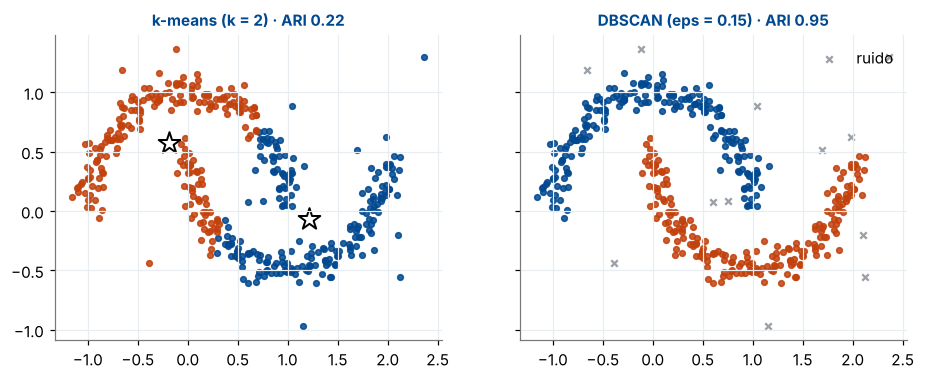

Grupos de DBSCAN: [0, 1] · puntos marcados como ruido: 12


In [7]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

X_m, y_m = make_moons(n_samples=400, noise=0.07, random_state=SEED)
rng = np.random.default_rng(SEED)
X_m = np.vstack([X_m, rng.uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])    # 20 puntos de ruido
y_m = np.concatenate([y_m, -np.ones(20, int)])

km_m = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X_m)
db_m = DBSCAN(eps=0.15, min_samples=6).fit(X_m)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
dibujar_grupos(axs[0], X_m, km_m.labels_, f"k-means (k = 2) · ARI {adjusted_rand_score(y_m, km_m.labels_):.2f}", km_m.cluster_centers_)
dibujar_grupos(axs[1], X_m, db_m.labels_, f"DBSCAN (eps = 0.15) · ARI {adjusted_rand_score(y_m, db_m.labels_):.2f}")
axs[1].legend(loc="upper right"); plt.show()
print("Grupos de DBSCAN:", sorted(int(g) for g in set(db_m.labels_) - {-1}), "· puntos marcados como ruido:", int(np.sum(db_m.labels_ == -1)))

### ¿Cómo elegir `eps`? El gráfico de k-distancias

Para cada punto calculamos la distancia a su `min_samples`-ésimo vecino y las ordenamos. Los puntos de los grupos tienen distancias pequeñas; el ruido, grandes. El **codo** de esa curva es un buen `eps`.

**Tu turno.** Calcula las k-distancias con `NearestNeighbors(n_neighbors=6)` y dibuja la curva ordenada.

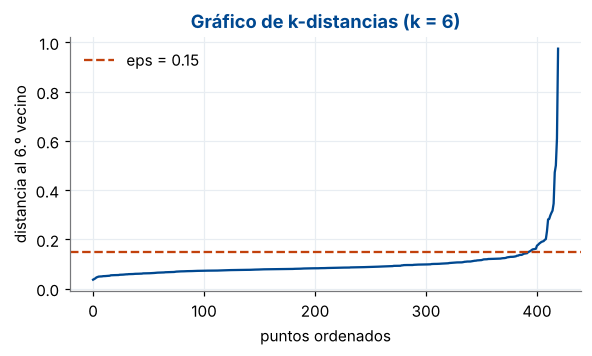

In [8]:
from sklearn.neighbors import NearestNeighbors

# TODO: kdist = distancia de cada punto a su 6.º vecino (el propio punto cuenta como el 1.º), ordenada de menor a mayor.
dist, _ = NearestNeighbors(n_neighbors=6).fit(X_m).kneighbors(X_m)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(6, 3)); plt.plot(kdist); plt.axhline(0.15, color=UNIBE["naranja"], ls="--", label="eps = 0.15")
plt.title("Gráfico de k-distancias (k = 6)"); plt.xlabel("puntos ordenados"); plt.ylabel("distancia al 6.º vecino"); plt.legend(); plt.show()
assert kdist[0] < kdist[-1]

**Experimento.** ¿Qué pasa con `eps` demasiado pequeño o demasiado grande?

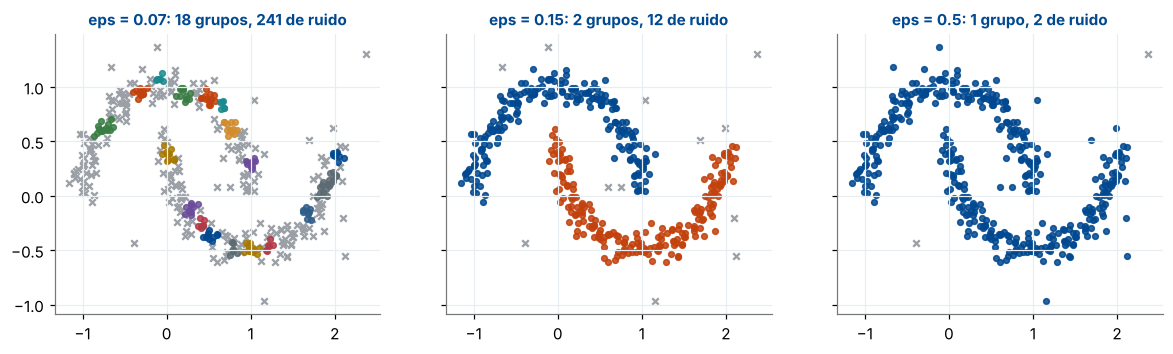

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, eps in zip(axs, [0.07, 0.15, 0.5]):
    lab = DBSCAN(eps=eps, min_samples=6).fit_predict(X_m)
    n_g, n_r = len(set(lab) - {-1}), int(np.sum(lab == -1))
    dibujar_grupos(ax, X_m, lab, f"eps = {eps}: {n_g} grupo{'s' if n_g != 1 else ''}, {n_r} de ruido")
plt.show()

Con `eps` pequeño casi todo es ruido y aparecen muchos grupos diminutos; con `eps` grande, las lunas se funden en un solo grupo. DBSCAN tiene un punto débil: un único `eps` para todo el conjunto, así que sufre si los grupos tienen **densidades muy distintas** (HDBSCAN lo resuelve; está en scikit-learn como `HDBSCAN`).

## Parte 4 · Mezclas de gaussianas (GMM)

Una **mezcla de gaussianas** supone que cada grupo es una nube gaussiana con su propia forma (matriz de covarianza). Se ajusta con el algoritmo **EM** (A2.13):

- **E (esperanza):** calcula la probabilidad de que cada punto venga de cada gaussiana (asignación **suave**).
- **M (maximización):** recalcula medias, covarianzas y pesos con esas probabilidades.

k-means es el caso límite de una GMM con covarianzas esféricas iguales y asignaciones duras. Cuando los grupos son **alargados**, la GMM gana.

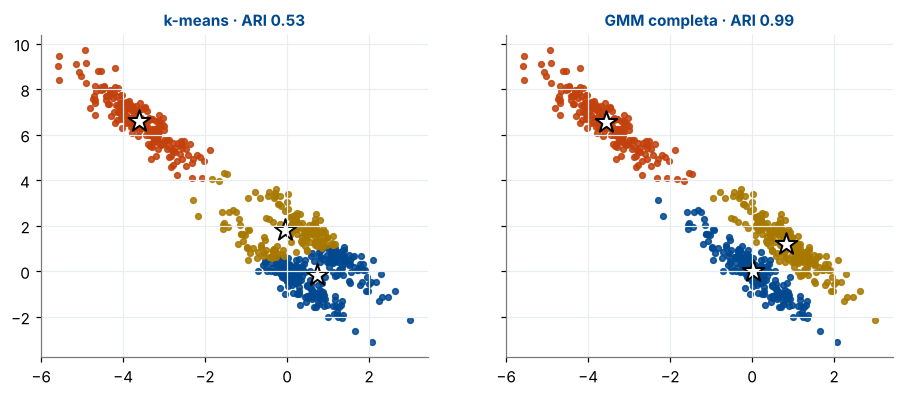

In [10]:
from sklearn.mixture import GaussianMixture

X_a, y_a = make_blobs(n_samples=600, centers=[[0, 0], [4, 4], [-2, 6]], cluster_std=1.0, random_state=SEED)
X_a = X_a @ np.array([[0.6, -0.6], [-0.4, 0.9]])          # transformación lineal: grupos estirados y girados
km_a = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_a)
gm_a = GaussianMixture(n_components=3, covariance_type="full", random_state=SEED).fit(X_a)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
dibujar_grupos(axs[0], X_a, km_a.labels_, f"k-means · ARI {adjusted_rand_score(y_a, km_a.labels_):.2f}", km_a.cluster_centers_)
dibujar_grupos(axs[1], X_a, gm_a.predict(X_a), f"GMM completa · ARI {adjusted_rand_score(y_a, gm_a.predict(X_a)):.2f}", gm_a.means_)
plt.show()

**Tu turno.** La GMM da **probabilidades**. Encuentra los 15 puntos más dudosos (probabilidad máxima más baja) y elige el número de componentes con el **BIC** (más bajo es mejor) para K = 1 a 6.

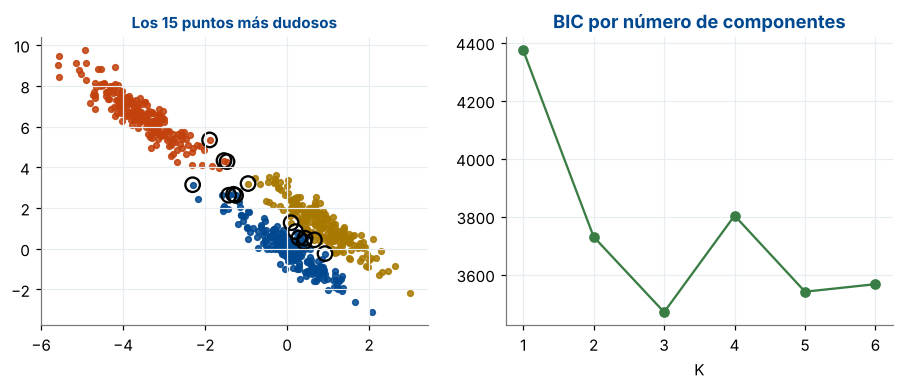

K con menor BIC: 3 · probabilidad mínima: 0.61


In [11]:
# TODO: prob_max = probabilidad de la componente más probable para cada punto; bics = lista de BIC para K = 1..6.
prob_max = gm_a.predict_proba(X_a).max(axis=1)
dudosos = np.argsort(prob_max)[:15]
bics = [GaussianMixture(n_components=K, covariance_type="full", random_state=SEED).fit(X_a).bic(X_a) for K in range(1, 7)]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
dibujar_grupos(axs[0], X_a, gm_a.predict(X_a), "Los 15 puntos más dudosos")
axs[0].scatter(X_a[dudosos, 0], X_a[dudosos, 1], s=90, facecolors="none", edgecolors="black", linewidths=1.5)
axs[1].plot(range(1, 7), bics, "o-", color=UNIBE["verde"]); axs[1].set_title("BIC por número de componentes"); axs[1].set_xlabel("K")
plt.show()
print("K con menor BIC:", int(np.argmin(bics)) + 1, "· probabilidad mínima:", prob_max.min().round(3))
assert int(np.argmin(bics)) + 1 == 3

Los puntos dudosos están en las fronteras entre nubes: k-means los asignaría con la misma seguridad que a los del centro. Esa **incertidumbre** es información útil (por ejemplo, para revisar clientes que no encajan en ningún segmento).

**Preguntas para la discusión (Clase 2):**

1. Un banco quiere segmentar 2 millones de clientes por gasto y frecuencia. ¿k-means, DBSCAN o GMM? ¿Qué preprocesamiento harías antes?
2. ¿Por qué el ARI no se puede usar en un problema real de clustering, y qué usarías en su lugar?
3. DBSCAN marcó puntos como ruido. ¿En qué problemas ese ruido es justamente lo que buscas?

> **Respuesta de referencia**

1. Con millones de filas y variables numéricas, k-means (o `MiniBatchKMeans`) es lo práctico: escala lineal con n. DBSCAN necesita buscar vecinos y elegir `eps`, más costoso y sensible; la GMM da probabilidades pero es más lenta y frágil en alta dimensión. Antes: tratar asimetrías (logaritmo del gasto), escalar, y quizá reducir dimensión. Luego validar los segmentos con el negocio, no solo con la silueta.
2. El ARI compara con etiquetas verdaderas, que en un problema real no existen (si existieran, sería un problema supervisado). Se usan métricas internas (silueta, Davies–Bouldin, BIC en GMM), estabilidad ante remuestreo y, sobre todo, la utilidad y la interpretabilidad para el negocio.
3. Detección de fraude, fallos de sensores, intrusiones en redes, errores de captura de datos: el ruido de DBSCAN es un primer detector de anomalías (Parte 3 de L2.2).

## Reto · Escala realista: agrupar dígitos sin etiquetas

¿Puede k-means descubrir los diez dígitos sin que nadie le diga cuál es cuál? Empezamos con los 1 797 dígitos de 8 × 8 de scikit-learn y miramos los **centroides como imágenes**: son «dígitos promedio».

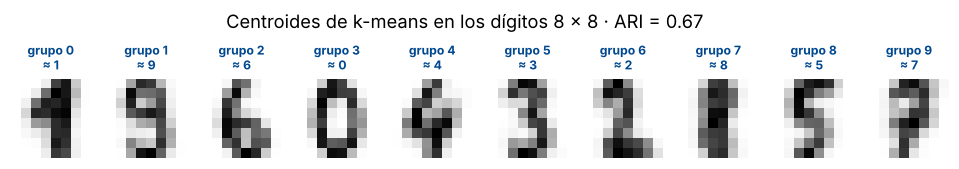

In [12]:
from sklearn.datasets import load_digits

dig = load_digits()
km_d = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit(dig.data)
fig, axs = plt.subplots(1, 10, figsize=(11, 1.5))
for j, ax in enumerate(axs):
    mayoria = np.bincount(dig.target[km_d.labels_ == j]).argmax()
    ax.imshow(km_d.cluster_centers_[j].reshape(8, 8), cmap="Greys"); ax.set_title(f"grupo {j}\n≈ {mayoria}", fontsize=8); ax.axis("off")
plt.suptitle(f"Centroides de k-means en los dígitos 8 × 8 · ARI = {adjusted_rand_score(dig.target, km_d.labels_):.2f}", y=1.15); plt.show()

Ahora **MNIST**: 10 000 imágenes de 28 × 28 = 784 variables. Primero reducimos a 50 componentes principales (lo verás en L2.2) para que las distancias tengan menos ruido y el cálculo sea rápido.

**Tu turno (reto).** Agrupa MNIST con k-means (k = 10) sobre las 50 componentes y calcula el ARI y la **pureza**: la fracción de imágenes cuyo dígito coincide con el dígito mayoritario de su grupo. Compara con `MiniBatchKMeans`, que procesa lotes y escala a millones de filas.

In [13]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

d = np.load(descargar("mnist.npz"))
idx = np.random.default_rng(SEED).choice(len(d["x_train"]), 10_000, replace=False)
X_mn, y_mn = d["x_train"][idx].reshape(-1, 784) / 255.0, d["y_train"][idx]
Z_mn = PCA(n_components=50, random_state=SEED).fit_transform(X_mn)


def pureza(y, grupos):
    """Fracción de puntos que coinciden con la etiqueta mayoritaria de su grupo."""
    return sum(np.bincount(y[grupos == g]).max() for g in np.unique(grupos)) / len(y)


# TODO (reto): entrena KMeans y MiniBatchKMeans (k = 10) sobre Z_mn; mide tiempo, ARI y pureza de cada uno.
filas = []
for nombre, modelo in [("KMeans", KMeans(n_clusters=10, n_init=10, random_state=SEED)),
                       ("MiniBatchKMeans", MiniBatchKMeans(n_clusters=10, n_init=10, batch_size=1024, random_state=SEED))]:
    t0 = time.perf_counter(); g = modelo.fit_predict(Z_mn); t = time.perf_counter() - t0
    filas.append({"modelo": nombre, "segundos": t, "ARI": adjusted_rand_score(y_mn, g), "pureza": pureza(y_mn, g)})
print(pd.DataFrame(filas).round(3).to_string(index=False))

         modelo  segundos   ARI  pureza
         KMeans     1.253 0.358   0.587
MiniBatchKMeans     0.248 0.353   0.554


Una pureza cercana al 60 % significa que k-means encuentra estructura real (muchos grupos son casi un solo dígito), pero **los grupos naturales no son las clases**: los 4 y los 9 se mezclan, y un mismo dígito escrito de dos formas puede partirse en dos grupos. Clustering no es clasificación sin etiquetas: es **descubrir** estructura, que luego interpreta una persona.

## Desafío opcional con IA agéntica · Segmentar clientes con un agente, sin perder el criterio

**Objetivo.** Pedirle a un asistente de IA que lleve el flujo de k-means y DBSCAN a un conjunto realista y revisar críticamente sus decisiones de preprocesamiento y de elección de k.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
Tengo el notebook resuelto L2.1 (k-means, DBSCAN y GMM con datos icónicos de scikit-learn). Muéstrame primero un plan y espera mi aprobación. Luego agrega una sección que agrupe las 13 medidas químicas del conjunto de vinos (sklearn.datasets.load_wine) sin usar la variedad: pipeline con StandardScaler, k-means con k de 2 a 8 (codo y silueta), DBSCAN con eps elegido con el gráfico de k-distancias, y una GMM elegida por BIC. Al final, y solo para evaluar, compara los grupos con la variedad usando el ARI. Explica en tres frases cuál método recomendarías y por qué.
```

**Cómo verificar el resultado**

- El escalado está dentro de un pipeline y se aplica antes de las tres técnicas.
- La variedad del vino no se usa para elegir k, eps ni el número de componentes; solo para el ARI final.
- La recomendación se apoya en las cifras (silueta, BIC, ARI) y menciona una limitación del método elegido.

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.